# Lightweight Hub’Eau hydrometric ingestion

This notebook downloads **one day of recent water-level and discharge observations for one station** using the [Hub’Eau Hydrométrie v2 API](https://hubeau.eaufrance.fr/page/api-hydrometrie). It keeps quality metadata, removes duplicates, saves a small CSV, and plots the two variables.

Default station: **La Seine à Paris — Austerlitz** (`F700000103`). No API key is required.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE_URL = "https://hubeau.eaufrance.fr/api/v2/hydrometrie"
STATION_CODE = "F700000103"
DAYS = 1
PAGE_SIZE = 20_000
MAX_PAGES = 10

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "hubeau"
OUTPUT_FILE = OUTPUT_DIR / f"{STATION_CODE}_recent.csv"

## 1. API client

Retries are limited to temporary failures. The observation endpoint currently filters stations with `code_entite`; pagination follows the API-provided `next` URL.

In [2]:
retry = Retry(
    total=3,
    connect=3,
    read=3,
    backoff_factor=1,
    status_forcelist=(429, 500, 502, 503, 504),
    allowed_methods=frozenset({"GET"}),
    respect_retry_after_header=True,
)
SESSION = requests.Session()
SESSION.mount("https://", HTTPAdapter(max_retries=retry))


def get_json(url, params=None):
    response = SESSION.get(url, params=params, timeout=30)
    response.raise_for_status()
    return response.json()


def fetch_recent_observations(station_code, days):
    start = datetime.now(timezone.utc) - timedelta(days=days)
    params = {
        "code_entite": station_code,
        "date_debut_obs": start.isoformat().replace("+00:00", "Z"),
        "size": PAGE_SIZE,
    }
    url = f"{BASE_URL}/observations_tr"
    rows = []

    for _ in range(MAX_PAGES):
        payload = get_json(url, params)
        rows.extend(payload.get("data", []))
        url = payload.get("next")
        params = None
        if not url:
            break
    else:
        raise RuntimeError("Pagination limit reached; reduce DAYS before retrying.")

    if not rows:
        raise ValueError("No observations returned for this station and period.")
    return pd.DataFrame(rows)

## 2. Station metadata

In [3]:
payload = get_json(
    f"{BASE_URL}/referentiel/stations",
    params={"code_station": STATION_CODE},
)
if payload.get("count") != 1:
    raise ValueError(f"Expected one station, received {payload.get('count')}.")

station = payload["data"][0]
station_summary = pd.Series(
    {
        "code": station["code_station"],
        "name": station["libelle_station"],
        "river": station.get("libelle_cours_eau"),
        "department": station.get("code_departement"),
        "longitude": station.get("longitude_station"),
        "latitude": station.get("latitude_station"),
        "active": station.get("en_service"),
    },
    name="value",
)
display(station_summary.to_frame())

,value
code,F700000103
name,La Seine à Paris - Austerlitz [>2006] - Statio...
river,La Seine
department,75
longitude,2.365511
latitude,48.84469
active,True


## 3. Download and validate observations

Hub’Eau returns water level (`H`) in millimetres and discharge (`Q`) in litres per second. Raw values and qualification/status fields are preserved.

In [4]:
raw = fetch_recent_observations(STATION_CODE, DAYS)

required_columns = {
    "code_station",
    "date_obs",
    "grandeur_hydro",
    "resultat_obs",
}
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Missing API fields: {sorted(missing_columns)}")

raw["date_obs"] = pd.to_datetime(raw["date_obs"], utc=True)
raw["resultat_obs"] = pd.to_numeric(raw["resultat_obs"], errors="coerce")
raw["unite"] = raw["grandeur_hydro"].map({"H": "mm", "Q": "L/s"})

columns = [
    "code_station",
    "date_obs",
    "grandeur_hydro",
    "resultat_obs",
    "unite",
    "code_qualification_obs",
    "libelle_qualification_obs",
    "code_statut",
    "libelle_statut",
    "longitude",
    "latitude",
]
observations = (
    raw[columns]
    .drop_duplicates(["code_station", "date_obs", "grandeur_hydro"], keep="last")
    .sort_values(["date_obs", "grandeur_hydro"], ascending=[False, True])
    .reset_index(drop=True)
)

assert observations["code_station"].eq(STATION_CODE).all()
assert observations["date_obs"].notna().all()
assert observations["resultat_obs"].notna().all()

print(f"{len(raw)} rows downloaded; {len(observations)} unique rows retained.")
display(
    observations.groupby(["grandeur_hydro", "libelle_statut"], dropna=False)
    .agg(rows=("resultat_obs", "size"), first=("date_obs", "min"), last=("date_obs", "max"))
)
display(observations.head())

488 rows downloaded; 488 unique rows retained.


rows                     first  \
grandeur_hydro libelle_statut                                   
H              Brute            283 2026-11-01 08:30:00+00:00   
Q              Brute              4 2026-11-02 07:45:00+00:00   
               Corrigée         201 2026-11-01 08:30:00+00:00   

                                                   last  
grandeur_hydro libelle_statut                            
H              Brute          2026-11-02 08:00:00+00:00  
Q              Brute          2026-11-02 08:00:00+00:00  
               Corrigée       2026-11-02 07:40:00+00:00

,code_station,date_obs,grandeur_hydro,resultat_obs,unite,code_qualification_obs,libelle_qualification_obs,code_statut,libelle_statut,longitude,latitude
0,F700000103,2026-11-02 08:00:00+00:00,H,953.0,mm,16,Non qualifiée,4,Brute,2.365511,48.84469
1,F700000103,2026-11-02 08:00:00+00:00,Q,84500.0,L/s,16,Non qualifiée,4,Brute,2.365511,48.84469
2,F700000103,2026-11-02 07:55:00+00:00,H,964.0,mm,16,Non qualifiée,4,Brute,2.365511,48.84469
3,F700000103,2026-11-02 07:55:00+00:00,Q,98400.0,L/s,16,Non qualifiée,4,Brute,2.365511,48.84469
4,F700000103,2026-11-02 07:50:00+00:00,H,961.0,mm,16,Non qualifiée,4,Brute,2.365511,48.84469


## 4. Save the lightweight CSV

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
observations.to_csv(OUTPUT_FILE, index=False, date_format="%Y-%m-%dT%H:%M:%SZ")
print(f"Saved: {OUTPUT_FILE}")
print(f"Size: {OUTPUT_FILE.stat().st_size / 1024:.1f} KiB")

Saved: D:\Projects\hydro\data\hubeau\F700000103_recent.csv
Size: 46.4 KiB


## 5. Quick inspection

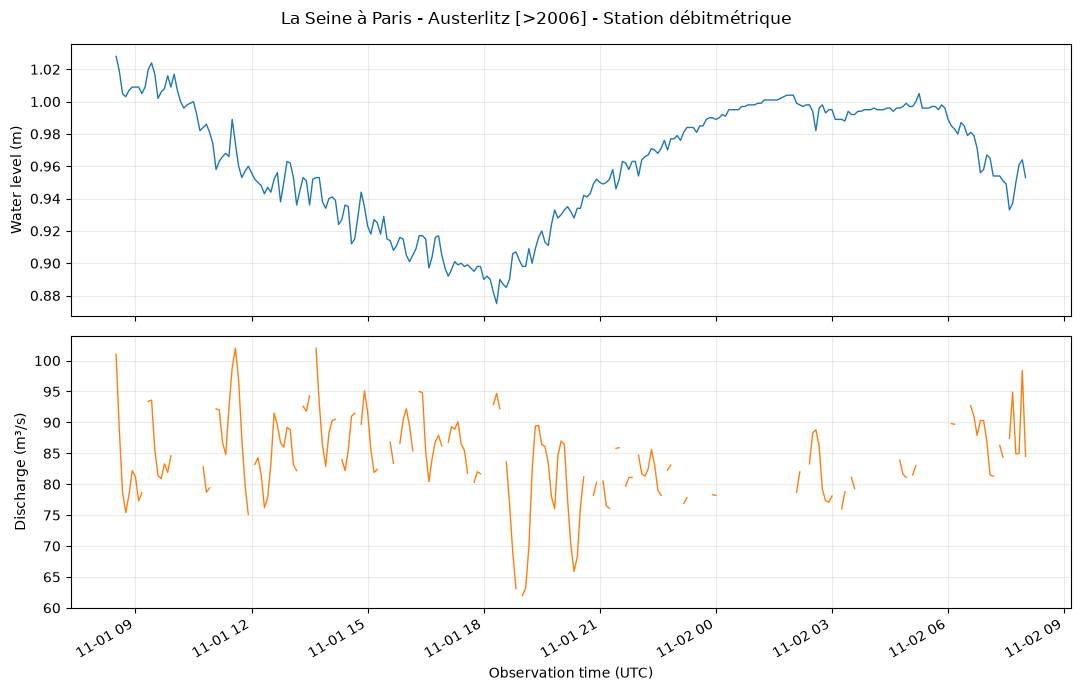

In [6]:
series = observations.pivot(
    index="date_obs",
    columns="grandeur_hydro",
    values="resultat_obs",
).sort_index()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
if "H" in series:
    axes[0].plot(series.index, series["H"] / 1000, color="tab:blue", linewidth=1)
    axes[0].set_ylabel("Water level (m)")
if "Q" in series:
    axes[1].plot(series.index, series["Q"] / 1000, color="tab:orange", linewidth=1)
    axes[1].set_ylabel("Discharge (m³/s)")
    axes[1].set_xlabel("Observation time (UTC)")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle(station["libelle_station"])
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

For a larger historical sample, increase `DAYS` gradually. The real-time endpoint exposes a rolling window, so a future scheduled collector should append new observations and deduplicate them with `(code_station, date_obs, grandeur_hydro)`.